# 01 · Setup and Data Preparation
**COMP-SCI 5567 Deep Learning · Video Object Tracking on MOT16**

This notebook gets everything ready for the rest of the project:

1. Downloads MOT16 (once) and unzips it on the Colab machine
2. Looks at the data: statistics table and a ground-truth video
3. Shows the data augmentation we use for detector training
4. Cuts out person crops for training the Siamese Re-ID network

Runtime: **T4 GPU**. Takes about 15–20 minutes the first time (mostly the download and the crop extraction), and about 2 minutes after that.

In [2]:
# ---- Setup (identical in every notebook) -----------------------------------
# The ONLY line you may need to change: where the project folder sits on your Drive.
# If a teammate shared the folder with you, right-click it in Drive ->
# "Organize" -> "Add shortcut" -> My Drive, and this path will work unchanged.
PROJECT_DIR = "/content/drive/MyDrive/DL_Project_MOT"

from google.colab import drive
drive.mount("/content/drive")

import os, sys
assert os.path.isdir(os.path.join(PROJECT_DIR, "src")), (
    f"Can't find {PROJECT_DIR}/src. Upload the project folder to Drive first (see README).")
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import config
paths = config.get_paths(PROJECT_DIR)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (switch the runtime to T4 GPU!)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: Tesla T4


## 1. Get MOT16

The zip (~1.9 GB) is saved in `DL_Project_MOT/data/` on Drive, so it is only downloaded once.
Every session, it is unzipped to `/content/MOT16` on the Colab machine, because reading thousands of frames directly from Drive is very slow.

**If you already have MOT16 unzipped somewhere on Drive**, put that folder path in `EXISTING_MOT16` and the notebook will zip your copy instead of downloading it again.

In [3]:
from mot_data import prepare_mot16

EXISTING_MOT16 = None   # e.g. "/content/drive/MyDrive/DL_Video_Tracking /MOT16"

MOT_ROOT = prepare_mot16(paths, existing_folder=EXISTING_MOT16)
print("Train:", sorted(os.listdir(f"{MOT_ROOT}/train")))
print("Test: ", sorted(os.listdir(f"{MOT_ROOT}/test")))

Unzipping MOT16.zip to /content/MOT16 ...
MOT16 ready at /content/MOT16
Train: ['MOT16-02', 'MOT16-04', 'MOT16-05', 'MOT16-09', 'MOT16-10', 'MOT16-11', 'MOT16-13']
Test:  ['MOT16-01', 'MOT16-03', 'MOT16-06', 'MOT16-07', 'MOT16-08', 'MOT16-12', 'MOT16-14']


## 2. What is in the data?

Each training video has a `gt/gt.txt` file with one line per person per frame:
`frame, id, left, top, width, height, flag, class, visibility`.

We only keep real pedestrians (`class == 1`) that the benchmark wants evaluated (`flag == 1`).
Static people, reflections, cars, etc. are dropped from training and treated as "don't care" during evaluation, exactly like the official benchmark does.

In [4]:
import pandas as pd
from mot_data import sequence_stats

stats = pd.DataFrame([sequence_stats(f"{MOT_ROOT}/train/{s}") for s in config.ALL_TRAIN_SEQS])
stats["role"] = ["validation" if s == config.VAL_SEQ else "training" for s in stats["sequence"]]
stats.to_csv(f"{paths.tables}/dataset_stats.csv", index=False)
stats

,sequence,frames,resolution,fps,identities,boxes,boxes_per_frame,role
0,MOT16-02,600,1920x1080,30,54,17833,29.7,training
1,MOT16-04,1050,1920x1080,30,83,47557,45.3,training
2,MOT16-05,837,640x480,14,125,6818,8.1,training
3,MOT16-09,525,1920x1080,30,25,5257,10.0,validation
4,MOT16-10,654,1920x1080,30,54,12318,18.8,training
5,MOT16-11,900,1920x1080,30,69,9174,10.2,training
6,MOT16-13,750,1920x1080,25,107,11450,15.3,training


**Our split.** MOT16-09 is held out as the validation video: the detector and the Re-ID network never see it during training, so the numbers we report on it are honest.
The other six videos are used for training. MOT16-01 (test set, no labels) is the video we submit.

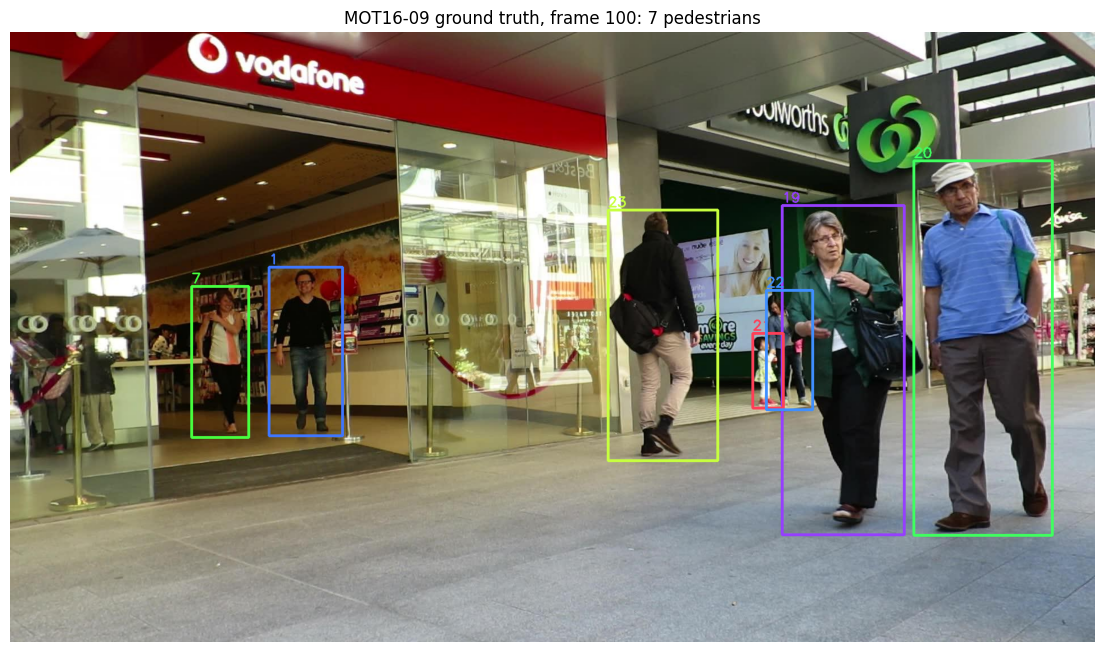

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mot_data import read_seqinfo, frame_path, parse_gt
from viz import id_color, render_tracks, show_video

seq_dir = f"{MOT_ROOT}/train/{config.VAL_SEQ}"
info = read_seqinfo(seq_dir)
gt = parse_gt(seq_dir)

# One annotated frame, saved as a figure for the slides
f = 100
img = cv2.imread(frame_path(seq_dir, info, f))
for tid, x1, y1, x2, y2 in gt[f]:
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), id_color(tid), 3)
    cv2.putText(img, str(int(tid)), (int(x1), int(y1) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.8, id_color(tid), 2)
plt.figure(figsize=(14, 8)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{config.VAL_SEQ} ground truth, frame {f}: {len(gt[f])} pedestrians")
plt.savefig(f"{paths.figures}/gt_example.jpg", dpi=120, bbox_inches="tight"); plt.show()

In [6]:
# A 5-second ground-truth clip. Our tracker's final output should look like this.
# (Half resolution so it is small enough to play inside the notebook.)
gt_tracks = {fr: np.c_[b, np.ones(len(b))] for fr, b in gt.items()}
clip = render_tracks(seq_dir, gt_tracks, f"{paths.videos}/gt_preview_{config.VAL_SEQ}.mp4",
                     max_frames=150, scale=0.5, title="Ground truth")
show_video(clip)

saved /content/drive/MyDrive/DL_Project_MOT/outputs/videos/gt_preview_MOT16-09.mp4


## 3. Data augmentation for the detector

The slides list augmentation as the first step of the pipeline. Our training set is only six videos, so we make every frame look slightly different each time it is seen:

* **Horizontal flip**: people walk both ways, and the boxes are flipped with the image
* **Colour jitter** (brightness, contrast, saturation): different lighting and cameras
* **Gaussian blur**: motion blur and out-of-focus people

These are the exact transforms from the project slides. Below, the same frame is shown four times with random augmentations.

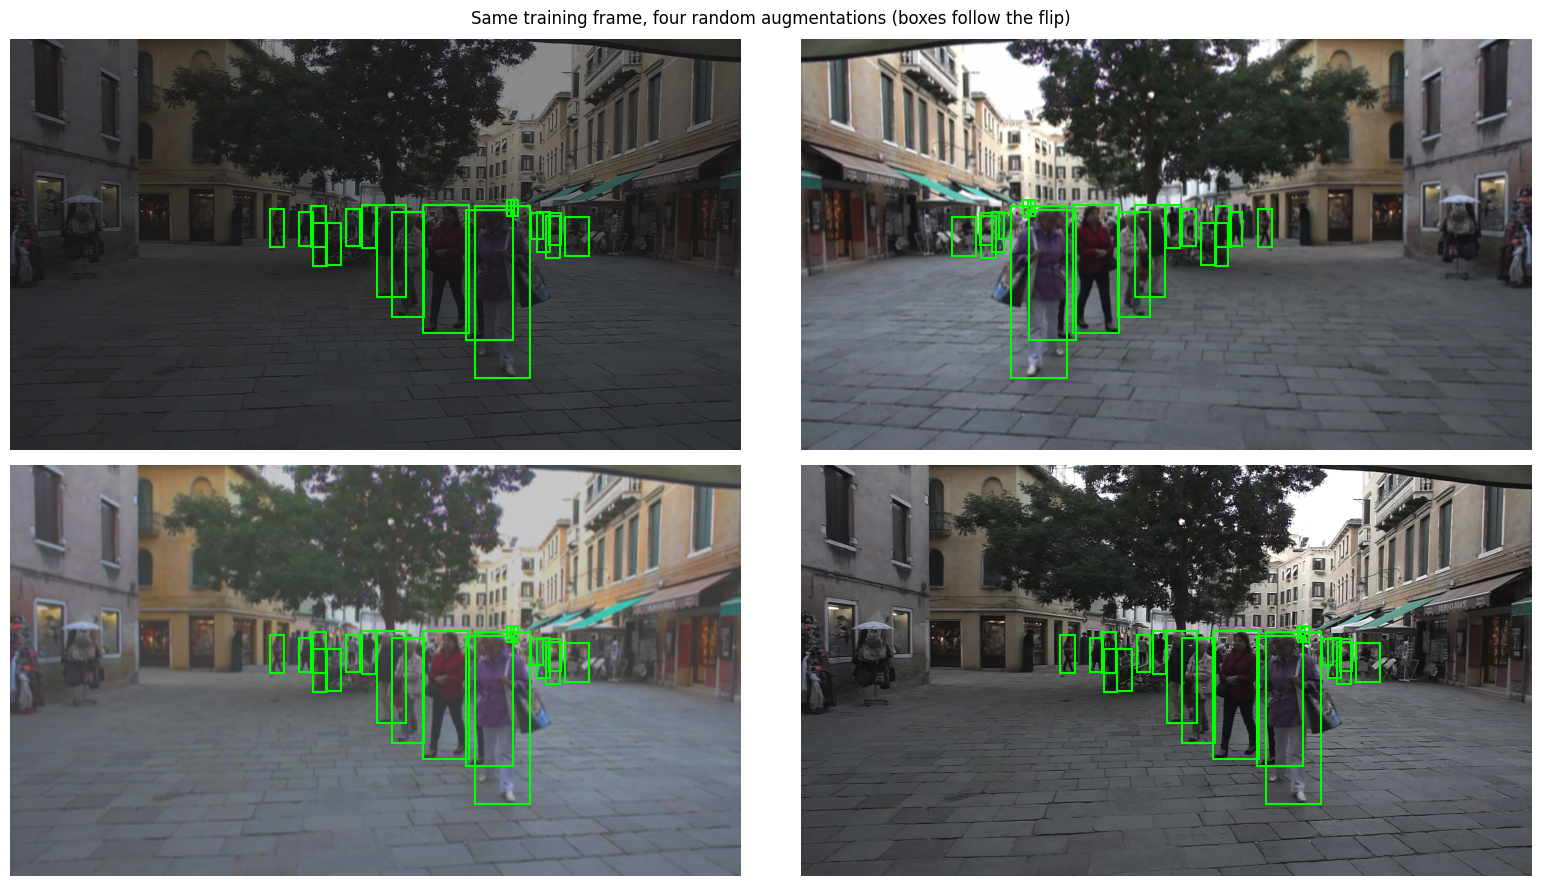

In [7]:
import matplotlib.patches as patches
from mot_data import MOT16DetectionDataset

aug_ds = MOT16DetectionDataset(MOT_ROOT, [config.TRAIN_SEQS[0]], frame_step=50, train=True)
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax in axes.ravel():
    image, target = aug_ds[3]           # same frame, new random augmentation each time
    ax.imshow(image.permute(1, 2, 0).numpy())
    for x1, y1, x2, y2 in target["boxes"].tolist():
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=1.5))
    ax.axis("off")
fig.suptitle("Same training frame, four random augmentations (boxes follow the flip)")
plt.tight_layout(); plt.savefig(f"{paths.figures}/augmentation_examples.jpg", dpi=110); plt.show()

## 4. Re-ID crops (training data for the Siamese network)

The Siamese network learns "same person or not?" from small crops of people.
MOT16 already tells us who is who (the `id` column), so we cut every visible person out of the frames and save the crops in one folder per person.

* `train/`: people from the six training videos
* `val/`: people from MOT16-09 only, so we test the network on **people it has never seen**, which is exactly the situation in the test video

We skip people smaller than 50 px or less than 50% visible: a crop that is mostly someone else's back would teach the network the wrong thing. We also take every 3rd frame, since consecutive frames are nearly identical.

In [8]:
import shutil
from mot_data import extract_reid_crops

if os.path.exists(paths.reid_zip):
    print("reid_crops.zip already exists on Drive, skipping. Delete it to rebuild.")
else:
    shutil.rmtree(paths.local_reid, ignore_errors=True)
    print("Training identities:")
    extract_reid_crops(MOT_ROOT, config.TRAIN_SEQS, paths.reid_train)
    print("\nValidation identities (MOT16-09):")
    extract_reid_crops(MOT_ROOT, [config.VAL_SEQ], paths.reid_val)
    # Zip once to Drive; notebook 03 unzips it to local disk in seconds
    shutil.make_archive(paths.reid_zip[:-4], "zip", root_dir="/content", base_dir="reid_crops")
    print("Saved", paths.reid_zip)

Training identities:
  MOT16-02: 2338 crops
  MOT16-04: 9648 crops
  MOT16-05: 1152 crops
  MOT16-10: 2848 crops
  MOT16-11: 1981 crops
  MOT16-13: 2286 crops
Total: 20253 crops of 415 people -> /content/reid_crops/train

Validation identities (MOT16-09):
  MOT16-09: 1039 crops
Total: 1039 crops of 24 people -> /content/reid_crops/val
Saved /content/drive/MyDrive/DL_Project_MOT/data/reid_crops.zip


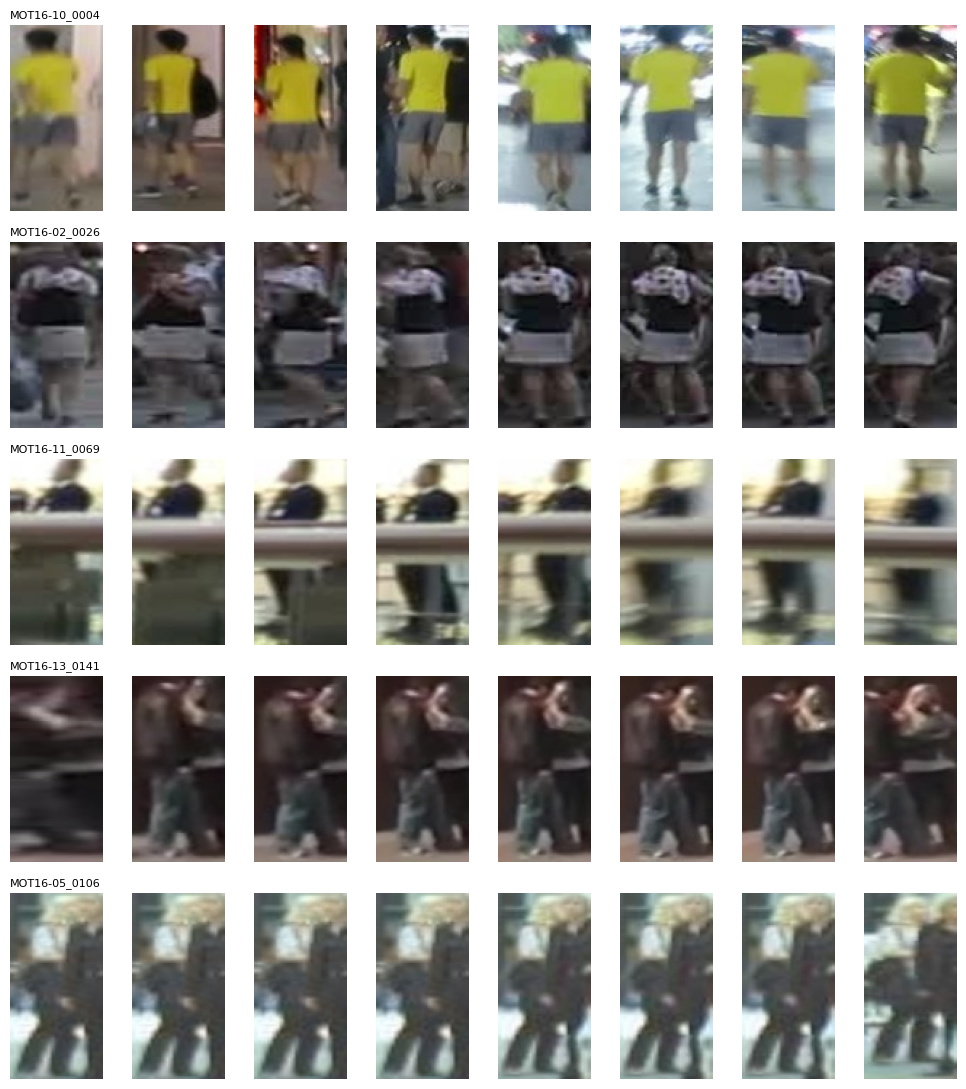

Train: 415 people, 20253 crops | Val: 24 unseen people


In [9]:
# Peek at the crops: each row is one person seen at different moments
from mot_data import prepare_reid_crops
prepare_reid_crops(paths)

people = sorted(os.listdir(paths.reid_train))
rng = np.random.default_rng(1)
fig, axes = plt.subplots(5, 8, figsize=(10, 11))
for r, pid in enumerate(rng.choice(people, 5, replace=False)):
    files = sorted(os.listdir(f"{paths.reid_train}/{pid}"))
    for c, i in enumerate(np.linspace(0, len(files) - 1, 8).astype(int)):
        crop = cv2.imread(f"{paths.reid_train}/{pid}/{files[i]}")
        axes[r, c].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
    axes[r, 0].set_title(pid, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{paths.figures}/reid_crops_examples.jpg", dpi=110); plt.show()

n_train = sum(len(os.listdir(f"{paths.reid_train}/{p}")) for p in people)
n_val_ids = len(os.listdir(paths.reid_val))
print(f"Train: {len(people)} people, {n_train} crops | Val: {n_val_ids} unseen people")

## Done ✅

Saved for later notebooks and the report:
* `data/MOT16.zip`, `data/reid_crops.zip`
* `results/tables/dataset_stats.csv`
* `results/figures/gt_example.jpg`, `augmentation_examples.jpg`, `reid_crops_examples.jpg`

**Next:** notebook 02 fine-tunes the Faster R-CNN detector. Notebooks 02 and 03 don't depend on each other, so two teammates can run them at the same time.